## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [1]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH = "/content/drive/MyDrive/ANN_Lab04_uci_health/heart_disease.csv"


## Cell 2 — Import Libraries

In [3]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [4]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
df = pd.read_csv(url, header=None, names=columns, na_values="?")

print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 303 rows, 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [5]:
print(df.shape)        # (rows, columns)
print(df.dtypes)       # data type of each column
df.head()              # first 5 rows
df.describe()          # summary stats (mean, std, min/max, quartiles) for numeric columns
df["target"].unique()  # distinct values the target variable takes

(303, 14)
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


array([0, 2, 1, 3, 4])

### Understanding the Dataset

The dataset contains **303 samples and 14 columns**, including **13 features and 1 target variable**. All feature columns are stored as `float64`, while the target is stored as `int64`.

The dataset includes features such as `age`, `sex`, `cp`, `trestbps`, `chol`, `thalach`, and others. The first few rows show the actual patient data and the different feature values.

The `describe()` function provides summary statistics such as the **mean, standard deviation, minimum, maximum, and quartiles** for the numerical columns.

The **target variable** is `target`, which takes **5 possible values: 0, 1, 2, 3, and 4**.

## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
target
0    54.125413
1    18.151815
2    11.881188
3    11.551155
4     4.290429
Name: proportion, dtype: float64


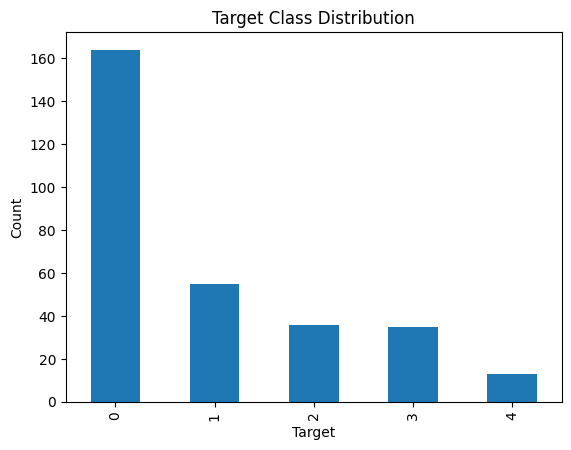

In [6]:
counts = df["target"].value_counts()                           # count per class
percentages = df["target"].value_counts(normalize=True) * 100  # % per class

print(counts)
print(percentages)

counts.plot(kind="bar")                                        # bar plot of class distribution
plt.xlabel("Target")
plt.ylabel("Count")
plt.title("Target Class Distribution")
plt.show()

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [7]:
print(df.isnull().sum())        # missing values per column ('?' already converted to NaN on load)
print(df.duplicated().sum())    # number of duplicate rows
print(df.dtypes)                # data type per column

for col in df.columns:
    print(col, df[col].nunique())  # unique value count per column

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
0
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object
age 41
sex 2
cp 4
trestbps 50
chol 152
fbs 2
restecg 3
thalach 91
exang 2
oldpeak 40
slope 3
ca 4
thal 3
target 5


### Handling Missing Values

Only `ca` and `thal` contain missing values. `ca` has 4 missing values and `thal` has 2 out of 303 rows, which is less than 2% of the data. Therefore, we will keep these rows instead of removing them.

Although both columns are stored as `float64`, they are actually **categorical variables** because they have only a few distinct values. So, using the mean to fill the missing values would not be appropriate. Instead, we will use the **mode (most frequent value)** for imputation.

We will handle this using `SimpleImputer(strategy="most_frequent")` in the preprocessing pipeline. The imputer will be fitted **only on the training data** to prevent **data leakage** from the test set.

## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

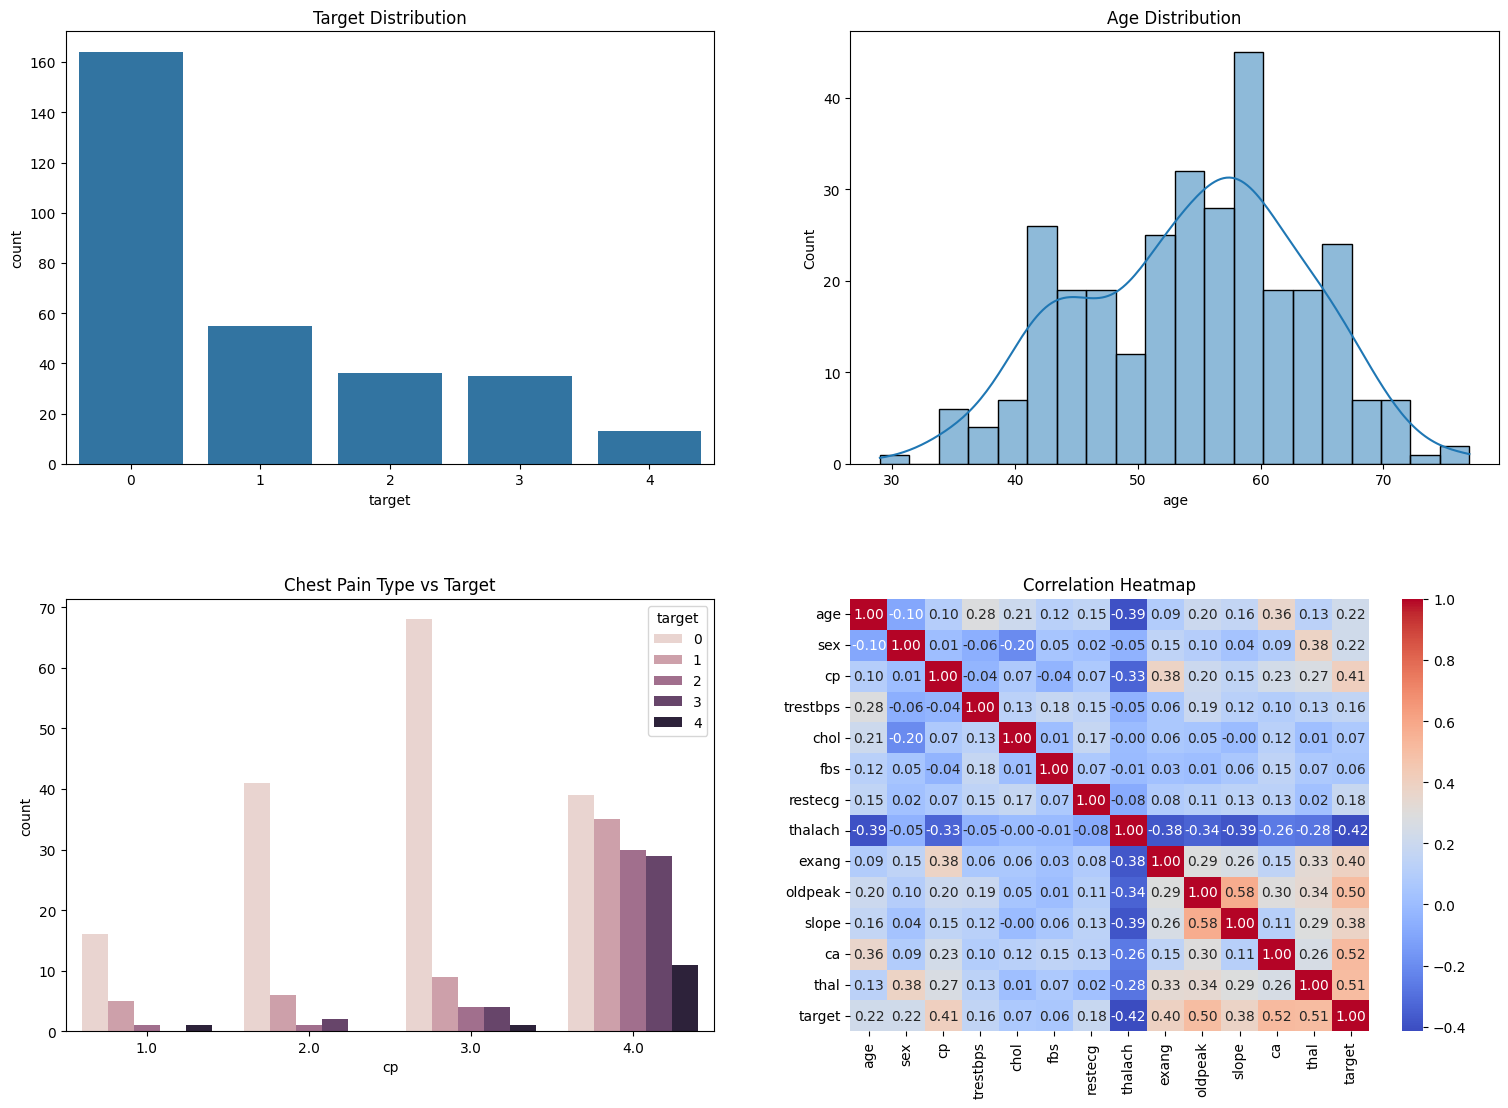

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# target distribution
sns.countplot(x="target", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Target Distribution")

# age distribution
sns.histplot(df["age"], bins=20, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Age Distribution")

# chest pain type vs target
sns.countplot(x="cp", hue="target", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Chest Pain Type vs Target")

# correlation heatmap of numerical features
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout(pad=4.0, w_pad=5.0, h_pad=5.0)
plt.show()

### Data Distribution and Correlation

The target distribution shows that **class 0 (no disease)** has the most samples, while the other classes have fewer samples.

The **age** of most patients is between 40 and 65, with a few younger and older patients.

For **chest pain type (`cp`)**, asymptomatic patients (`cp = 4`) make up a large portion of the disease-positive cases.

The **correlation heatmap** shows that most numerical features do not have strong linear relationships with each other. However, features such as `thalach` (maximum heart rate) and `oldpeak` show some relationship with the target.

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [9]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# binarize target: 0 = no disease, 1-4 -> 1 = disease present
X = df.drop(columns=["target"])
y = (df["target"] > 0).astype(int)

# numerical vs categorical features
numerical_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# first split off the test set (30%), kept fully isolated from here on
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# split remaining training data into train/val (e.g. 80/20 of the 70%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full
)

# numerical: no missing values here, median imputer kept as a safe default + scale
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# categorical: ca and thal have missing values -> impute with mode (per Cell 6 decision) + one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# fit only on training data, then transform train/val/test
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# convert to PyTorch tensors
X_train = torch.tensor(X_train_processed, dtype=torch.float32)
X_val = torch.tensor(X_val_processed, dtype=torch.float32)
X_test = torch.tensor(X_test_processed, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.long)
y_val = torch.tensor(y_val.values, dtype=torch.long)
y_test = torch.tensor(y_test.values, dtype=torch.long)

print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([169, 28]) torch.Size([43, 28]) torch.Size([91, 28])


In [10]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

### Data Preprocessing

First, I separated the dataset into **features (`X`)** and the **target (`y`)**. I converted the original target into a binary target: **0 = no disease** and **1 = disease present**, since this task only requires binary classification.

I divided the features into **numerical** and **categorical** columns. Numerical features include `age`, `trestbps`, `chol`, `thalach`, and `oldpeak`. The remaining features were treated as categorical.

I split the data into **70% training and 30% testing** using `random_state=42`, keeping the test set fully isolated from this point onward. From the remaining 70% training data, I set aside a further 20% as a **validation set**, so the model's performance during training could be monitored on unseen data without ever touching the test set.

For the categorical features, I filled the missing values in `ca` and `thal` using the **most frequent value (mode)** and then applied **one-hot encoding**. For the numerical features, I used **standard scaling** so that all features are on a similar scale, which helps the neural network train properly.

A `ColumnTransformer` was used to apply all these preprocessing steps together. It was fitted only on the training data and then used to transform the training, validation, and testing data.

After one-hot encoding, the number of features increased from **13 to 28** because some categorical features were converted into multiple binary columns.

Finally, the processed data was converted into **PyTorch tensors** and placed into `TensorDataset` and `DataLoader` objects for the train, validation, and test sets. Given the small size of the dataset, I used a **batch size of 16** so the model gets more frequent parameter updates per epoch.

## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |      28 | —          |
| Hidden 1 |      64 | ReLU       |
| Hidden 2 |      32 | ReLU       |
| Hidden 3 |      16 | ReLU       |
| Output   |       2 | —          |

*(Deleted Hidden 4 row — this design uses 3 hidden layers.)*

## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

Complete the table:

| Layer    | Input Units | Output Units | Calculation    | Parameters |
|----------|------------:|--------------:|-----------------|-----------:|
| Hidden 1 |          28 |            64 | (28 × 64) + 64  |      1,856 |
| Hidden 2 |          64 |            32 | (64 × 32) + 32  |      2,080 |
| Hidden 3 |          32 |            16 | (32 × 16) + 16  |        528 |
| Output   |          16 |             2 | (16 × 2) + 2    |         34 |
| **Total**|             |               |                 |  **4,498** |

Later, compare this total to what `model.summary()` reports in Cell 11.

## Cell 11 — Implement Neural Network in PyTorch


In [11]:
class MyModel(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(16, output_dim)
        )

    def forward(self, x):
        return self.model(x)

model = MyModel(input_dim=X_train.shape[1], output_dim=2)
print(model)

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.4, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=16, out_features=2, bias=True)
  )
)


In [12]:
# verify manual parameter count from Cell 10 matches the actual model
total_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {total_params}")

Total trainable parameters: 4498


### Neural Network Architecture

I implemented the neural network using `nn.Sequential`. The input layer has **28 features**, matching the preprocessed data from Cell 8.

The network has **three hidden layers** with **64, 32, and 16 neurons**, respectively. Each hidden layer uses the **ReLU activation function**, followed by **dropout** (0.5, 0.4, and 0.3 respectively) to reduce the network's reliance on any single neuron and help it generalize better, since the dataset is fairly small relative to the number of parameters.

The final output layer has **2 neurons** for the two classes: no disease and disease. No activation function was added to the output layer because `CrossEntropyLoss` handles the softmax operation internally.

To verify the parameter calculation from Cell 10, I used:

`sum(p.numel() for p in model.parameters())`

The model has exactly **4,498 trainable parameters**, which matches the manual calculation and confirms that the parameter formula was applied correctly. This count only includes the linear layers, since dropout has no trainable parameters of its own.

## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [13]:
loss_function = nn.CrossEntropyLoss()

### Loss Function

I used `CrossEntropyLoss` because the model has **2 output logits** for binary classification. It applies softmax internally, so no softmax activation is needed in the model. It also penalizes confident incorrect predictions more strongly.

## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [14]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-3)

### Optimizer

I used the **Adam optimizer** because it adapts the learning rate for each parameter and generally converges faster and more reliably than standard SGD. I used a learning rate of **0.0005**, slightly lower than the typical default, to take smaller, more careful steps given the small size of the dataset. I also added **weight decay (1e-3)**, which applies L2 regularization by penalizing large weights, helping the model generalize better instead of fitting too closely to the training data.

## Cell 14 — Compile the Model

In [15]:
num_epochs = 50
patience = 5

history = {"train_loss": [], "val_loss": []}

best_val_loss = float("inf")
epochs_no_improve = 0
best_model_state = None

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = loss_function(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = loss_function(outputs, y_batch)
            running_val_loss += loss.item() * X_batch.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)

    print(f"Epoch {epoch+1}/{num_epochs} - train_loss: {epoch_train_loss:.4f} - val_loss: {epoch_val_loss:.4f}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        epochs_no_improve = 0
        best_model_state = model.state_dict()
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping triggered at epoch {epoch+1} (best val_loss: {best_val_loss:.4f})")
            break

model.load_state_dict(best_model_state)

Epoch 1/50 - train_loss: 0.6854 - val_loss: 0.6854
Epoch 2/50 - train_loss: 0.6823 - val_loss: 0.6833
Epoch 3/50 - train_loss: 0.6824 - val_loss: 0.6802
Epoch 4/50 - train_loss: 0.6802 - val_loss: 0.6762
Epoch 5/50 - train_loss: 0.6777 - val_loss: 0.6704
Epoch 6/50 - train_loss: 0.6741 - val_loss: 0.6630
Epoch 7/50 - train_loss: 0.6656 - val_loss: 0.6540
Epoch 8/50 - train_loss: 0.6601 - val_loss: 0.6430
Epoch 9/50 - train_loss: 0.6471 - val_loss: 0.6284
Epoch 10/50 - train_loss: 0.6231 - val_loss: 0.6100
Epoch 11/50 - train_loss: 0.6191 - val_loss: 0.5883
Epoch 12/50 - train_loss: 0.5943 - val_loss: 0.5625
Epoch 13/50 - train_loss: 0.5783 - val_loss: 0.5360
Epoch 14/50 - train_loss: 0.5464 - val_loss: 0.5052
Epoch 15/50 - train_loss: 0.5430 - val_loss: 0.4775
Epoch 16/50 - train_loss: 0.5030 - val_loss: 0.4569
Epoch 17/50 - train_loss: 0.5240 - val_loss: 0.4392
Epoch 18/50 - train_loss: 0.5026 - val_loss: 0.4308
Epoch 19/50 - train_loss: 0.4903 - val_loss: 0.4116
Epoch 20/50 - train_l

<All keys matched successfully>

## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

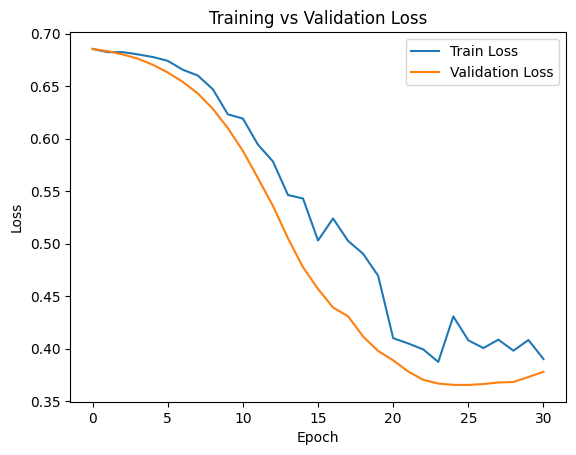

In [16]:
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [17]:
model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(X_batch)
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # probability of class 1
        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

accuracy = accuracy_score(y_true, y_pred_nn)
precision = precision_score(y_true, y_pred_nn, zero_division=0)
recall = recall_score(y_true, y_pred_nn, zero_division=0)
f1 = f1_score(y_true, y_pred_nn, zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

Accuracy : 0.8791
Precision: 0.8974
Recall   : 0.8333
F1-score : 0.8642


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [18]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(random_state=42)

# AdaBoost uses the same preprocessed features, but as numpy arrays (not tensors)
ada_model.fit(X_train.numpy(), y_train.numpy())

y_pred_ada = ada_model.predict(X_test.numpy())

accuracy_ada = accuracy_score(y_test.numpy(), y_pred_ada)
precision_ada = precision_score(y_test.numpy(), y_pred_ada, zero_division=0)
recall_ada = recall_score(y_test.numpy(), y_pred_ada, zero_division=0)
f1_ada = f1_score(y_test.numpy(), y_pred_ada, zero_division=0)

print(f"Accuracy : {accuracy_ada:.4f}")
print(f"Precision: {precision_ada:.4f}")
print(f"Recall   : {recall_ada:.4f}")
print(f"F1-score : {f1_ada:.4f}")

Accuracy : 0.8242
Precision: 0.7826
Recall   : 0.8571
F1-score : 0.8182


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |   0.8791 |    0.8974 | 0.8333 |   0.8642 |
| AdaBoost       |   0.8242 |    0.7826 | 0.8571 |   0.8182 |

**Discuss:**

**Differences in the evaluation metrics between the two models:** The neural network outperforms AdaBoost on accuracy, precision, and F1-score, while AdaBoost has a slightly higher recall (85.71% vs 83.33%). The biggest difference is in precision, with the neural network at 89.74% compared to AdaBoost's 78.26%, meaning the network produces fewer false positives when predicting disease.

**Possible reasons for the differences:** The neural network can learn more complex, non-linear relationships across the 28 preprocessed features, while AdaBoost, being an ensemble of simple decision stumps, is more limited in the patterns it can capture, especially on a dataset this small with only around 170 training samples. The regularization applied to the network, including dropout and weight decay, let it use its extra capacity without overfitting as badly as it did before tuning. AdaBoost's slightly higher recall suggests it catches a few more true positive cases, even though it is less precise overall.

**Whether the neural network shows signs of overfitting:** Looking back at the training and validation loss curves from Cell 15, the network doesn't show strong overfitting after tuning. Validation loss closely tracked training loss for most of training, and early stopping restored the best performing weights rather than the final epoch. The test set results are consistent with the validation performance rather than showing a big drop that would suggest memorization.

**How preprocessing may have affected performance:** Standard scaling on numerical features and one hot encoding on categorical ones likely helped both models, but probably helped the neural network more, since neural networks are especially sensitive to feature scale, unlike tree based methods like AdaBoost which are scale invariant. This may partly explain why the network made better use of the data despite the small dataset size.

In [19]:
comparison = pd.DataFrame({
    "Model": ["Neural Network", "AdaBoost"],
    "Accuracy": [accuracy, accuracy_ada],
    "Precision": [precision, precision_ada],
    "Recall": [recall, recall_ada],
    "F1-Score": [f1, f1_ada]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network,0.879121,0.897436,0.833333,0.864198
1,AdaBoost,0.824176,0.782609,0.857143,0.818182


## Cell 20 — Final Interpretation

**1. Whether the dataset is balanced or imbalanced:** The dataset is imbalanced. Looking at the original target distribution, class 0 (no disease) had roughly 164 samples while the other classes (1-4) were much smaller individually. Even after collapsing to a binary target, class 0 remains the majority class.

**2. The important preprocessing steps I applied:** I separated features and target, binarized the target for binary classification, and split the data into 70% training and 30% testing, with a further validation split carved out of the training set so the test set stayed fully isolated. I identified `ca` and `thal` as the only columns with missing values and imputed them with the mode, since both are categorical despite being stored as floats. Categorical features were one-hot encoded and numerical features were standard scaled, all inside a `ColumnTransformer` fitted only on the training data to avoid leakage.

**3. My neural network architecture and design choices:** I built a 3-hidden-layer network (64, 32, 16 neurons) with ReLU activations and dropout (0.5, 0.4, 0.3) after each hidden layer, ending in a 2-neuron output layer for binary classification. The architecture has 4,498 trainable parameters, verified against my manual calculation. Given the small dataset size (~170 training samples), I added dropout and weight decay to prevent the model from overfitting, and used early stopping with a patience of 5 epochs to stop training once validation loss stopped improving.

**4. Neural network evaluation results:** On the test set, the neural network achieved 87.91% accuracy, 89.74% precision, 83.33% recall, and an F1-score of 0.8642. Precision being higher than recall suggests the model is a bit conservative, missing some actual disease cases while being reliable when it does predict disease.

**5. AdaBoost evaluation results:** AdaBoost achieved 82.42% accuracy, 78.26% precision, 85.71% recall, and an F1-score of 0.8182 on the same test set.

**6. Comparison between the two models:** The neural network outperformed AdaBoost on accuracy, precision, and F1-score, while AdaBoost had a slightly higher recall. This suggests the neural network, after tuning for this small dataset, was better able to capture the underlying patterns in the data than AdaBoost's ensemble of simple decision stumps, though AdaBoost caught marginally more true positive cases.

**7. Possible improvements for future work:** With more data, the neural network's higher capacity could likely be used more effectively without needing as much regularization. Other improvements could include k-fold cross-validation to get a more robust estimate of performance given the small dataset, hyperparameter tuning via grid or random search instead of manual adjustment, and trying other ensemble methods like Gradient Boosting or Random Forests for comparison against AdaBoost.